## Step 6: Do the groups really live different lengths of time?

Steps 4 and 5 showed which genes and pathways differ between the groups. This step checks the question that matters most, which is whether the groups actually differ in how long patients live.

A few ideas first.

- **Kaplan-Meier curve.** A line that starts at 100% and drops each time a patient dies. Many patients are still alive when the data ends, and the curve handles that properly. This is why I use it and not a simple average of the follow-up months.
- **Median survival.** The point where the curve crosses 50%, meaning half of the patients have died. If fewer than half have died, the curve never gets there and the median is "Not reached." That is common in the slower groups.
- **Log-rank test.** Asks whether two curves are different by more than chance. A small p-value means they are.
- **Hazard ratio.** From a Cox model, which lets me account for age and sex at the same time. A hazard ratio of 2 means that at any moment, one group is twice as likely to die as the other. A hazard ratio of 1 means no difference. Age is included because IDH wild-type patients are about 20 years older, and the Ceccarelli paper found age was the strongest single predictor.

I use the three families from the paper (IDH wild-type, IDH mutant without 1p/19q codeletion, and IDH mutant with codeletion) so I can compare my medians to theirs. Then I use my three comparisons from step 3.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, pairwise_logrank_test
from lifelines.utils import median_survival_times

plt.rcParams["font.size"] = 20

coral = "#F26D5B"
light_blue = "#7DB9E8"
pink = "#F28DB2"

Path("csv").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

data_dir = Path.home() / "Desktop" / "PROJECT_4_PORT"
print("Done")

Done


### Load the patients and keep the ones with survival
Two patients have no survival information, so they are left out of this step.

In [2]:
patient_table = pd.read_csv("csv/patient_groups.csv")
survival = patient_table.dropna(subset=["OS_MONTHS", "event"]).copy()
survival["event"] = survival["event"].astype(int)

print("Patients in the table:", len(patient_table))
print("Patients with survival:", len(survival))
print("Deaths:", int(survival["event"].sum()))
print("Patients with zero or negative months:", int((survival["OS_MONTHS"] <= 0).sum()))

Patients in the table: 667
Patients with survival: 665
Deaths: 245
Patients with zero or negative months: 3


### Helper functions
The first function draws a Kaplan-Meier curve for each group, with a shaded band for the uncertainty. The second turns a group's median into text, including "Not reached" when the curve never drops to 50%.

In [3]:
def median_text(fitter):
    median = fitter.median_survival_time_
    if not np.isfinite(median):
        return "Not reached"
    interval = median_survival_times(fitter.confidence_interval_)
    low, high = interval.iloc[0, 0], interval.iloc[0, 1]
    low_text = "not reached" if not np.isfinite(low) else str(round(low, 1))
    high_text = "not reached" if not np.isfinite(high) else str(round(high, 1))
    return str(round(median, 1)) + " (" + low_text + " to " + high_text + ")"


def survival_curves(data, column, order, colors, title, filename, max_months=180):
    fig, ax = plt.subplots(figsize=(13, 8))
    rows = []
    for group in order:
        part = data[data[column] == group]
        fitter = KaplanMeierFitter()
        fitter.fit(part["OS_MONTHS"], part["event"], label=group + " (" + str(len(part)) + ")")
        fitter.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2, color=colors[group], linewidth=3)
        rows.append({"group": group, "patients": len(part), "deaths": int(part["event"].sum()),
                     "median_months": median_text(fitter)})
    ax.set_title(title)
    ax.set_xlabel("Months Since Diagnosis")
    ax.set_ylabel("Share Still Alive")
    ax.set_xlim(0, max_months)
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.4)
    ax.set_axisbelow(True)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=16)
    plt.tight_layout()
    plt.savefig("figures/" + filename, dpi=150, bbox_inches="tight")
    plt.show()
    return pd.DataFrame(rows).set_index("group")

print("Done")

Done


### The three families from the paper
First the patient counts, to make sure the labels look right. Then the curves and the medians. The paper reports median survival of 14.0 months for IDH wild-type, 75.1 months for IDH mutant without codeletion, and 115.8 months for IDH mutant with codeletion. My numbers will be close but not identical. My patients are only the ones with gene activity data (665 and not the paper's full group of about 974), and my follow-up is more recent.

In [4]:
print(survival["IDH_CODEL_SUBTYPE"].value_counts(dropna=False).to_string())

IDH_CODEL_SUBTYPE
IDHmut-non-codel    257
IDHwt               229
IDHmut-codel        167
NaN                  12


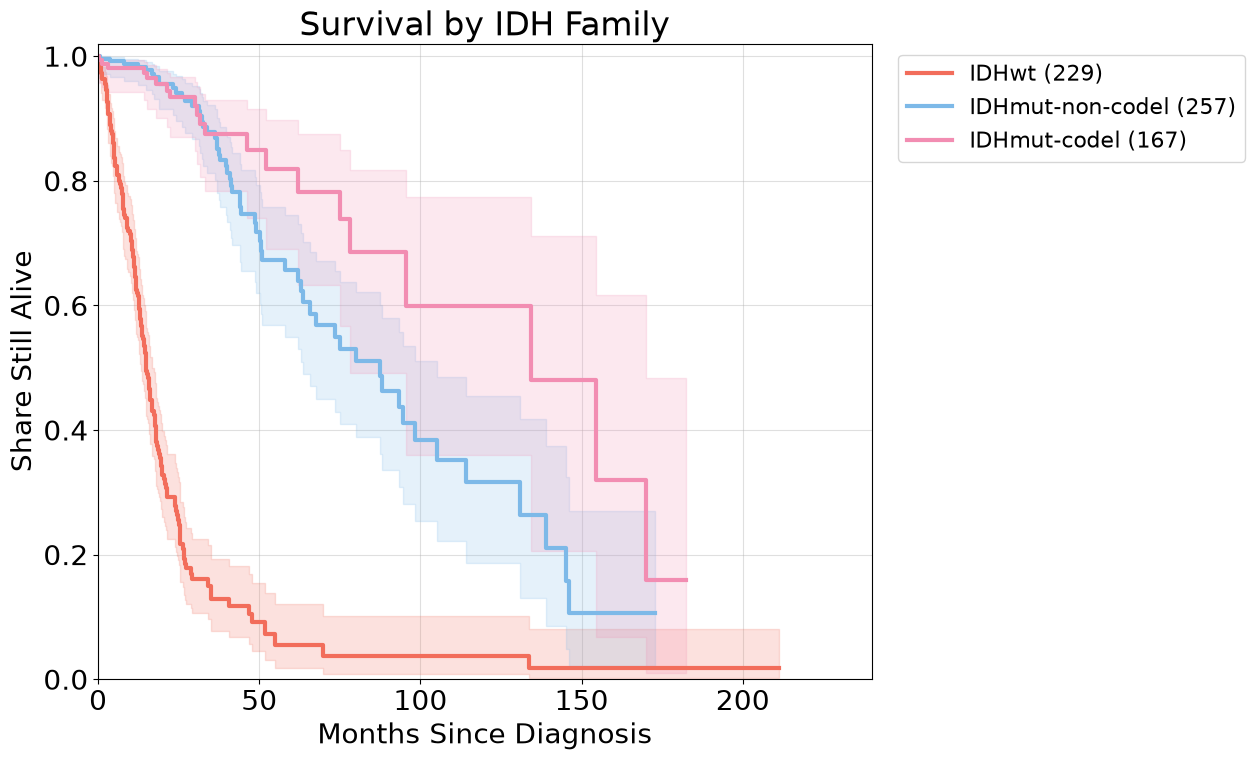

                  patients  deaths          median_months  paper_median_months
group                                                                         
IDHwt                  229     160    15.0 (13.3 to 16.8)                 14.0
IDHmut-non-codel       257      57   87.5 (63.5 to 105.2)                 75.1
IDHmut-codel           167      21  134.3 (78.2 to 169.8)                115.8


In [5]:
families = ["IDHwt", "IDHmut-non-codel", "IDHmut-codel"]
family_colors = {"IDHwt": coral, "IDHmut-non-codel": light_blue, "IDHmut-codel": pink}
paper_medians = {"IDHwt": 14.0, "IDHmut-non-codel": 75.1, "IDHmut-codel": 115.8}

family_data = survival[survival["IDH_CODEL_SUBTYPE"].isin(families)]
family_table = survival_curves(family_data, "IDH_CODEL_SUBTYPE", families, family_colors,
                               "Survival by IDH Family", "p4-survival-families.png", max_months=240)
family_table["paper_median_months"] = pd.Series(paper_medians)
print(family_table.to_string())

Now the log-rank tests, which compare each pair of families.

In [6]:
pairs = pairwise_logrank_test(family_data["OS_MONTHS"], family_data["IDH_CODEL_SUBTYPE"], family_data["event"])
print("Log-rank p-values for each pair of families")
print(pairs.summary[["p"]].to_string())

Log-rank p-values for each pair of families
                                              p
IDHmut-codel     IDHmut-non-codel  5.392582e-02
                 IDHwt             8.032468e-38
IDHmut-non-codel IDHwt             1.127419e-51


### My three comparisons
These are the same groups from steps 3 to 5, so the survival result lines up with the gene and pathway results. A positive direction means the first group has the shorter survival.

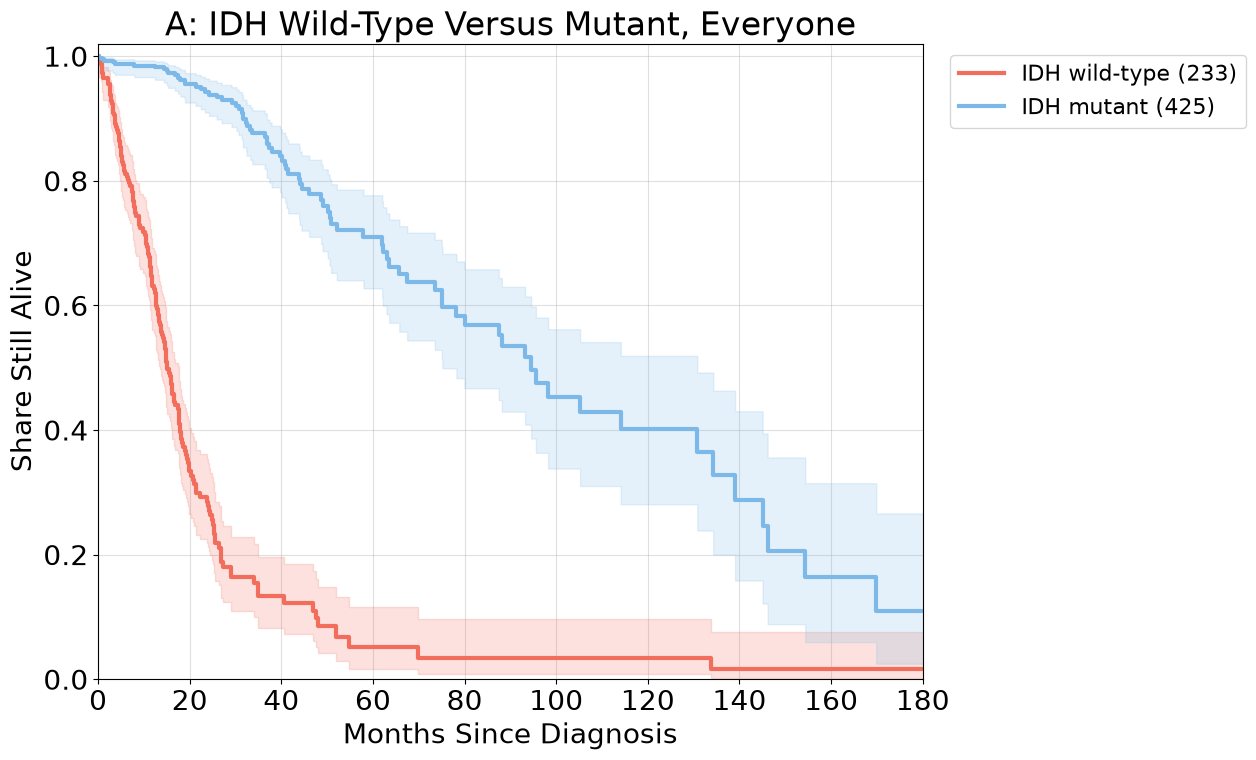

Comparison A
               patients  deaths         median_months
group                                                
IDH wild-type       233     163   15.1 (13.6 to 17.6)
IDH mutant          425      78  94.5 (75.2 to 130.8)
Log-rank p-value: 1.37e-77




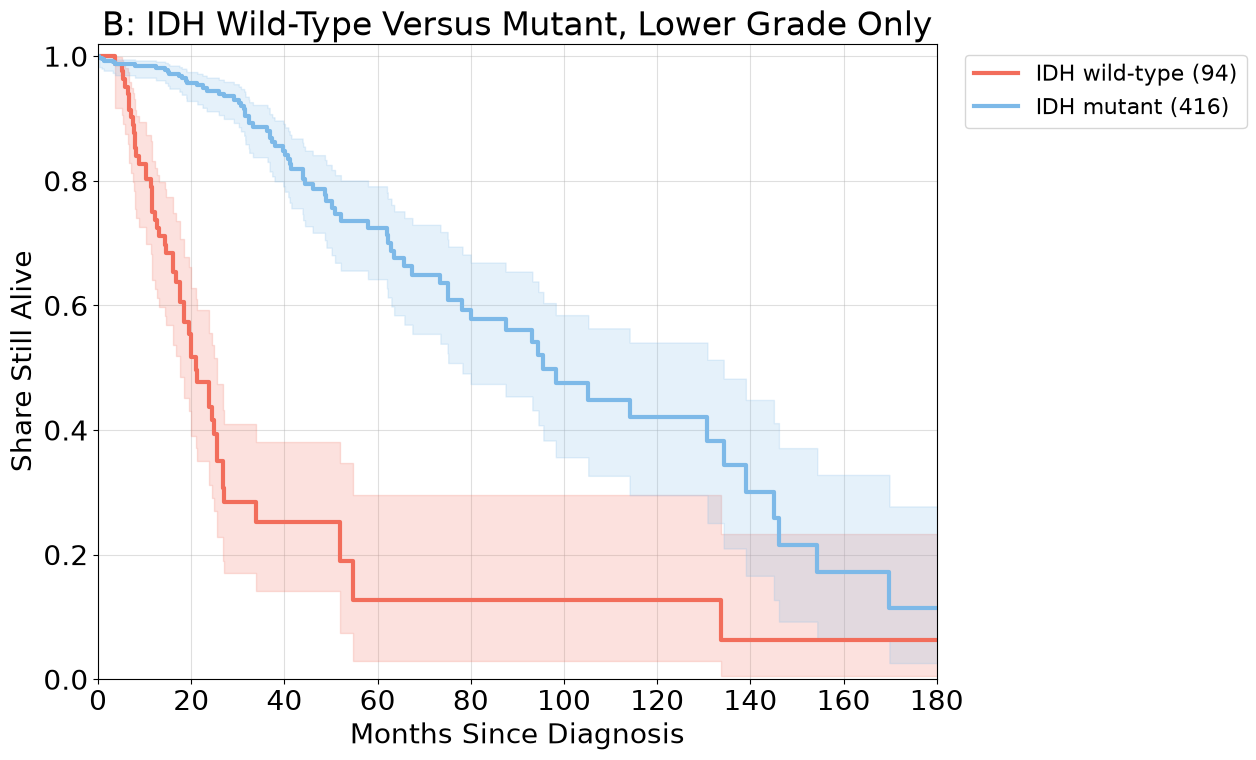

Comparison B
               patients  deaths         median_months
group                                                
IDH wild-type        94      50   21.0 (17.7 to 25.5)
IDH mutant          416      73  95.6 (78.2 to 134.3)
Log-rank p-value: 4.79e-29




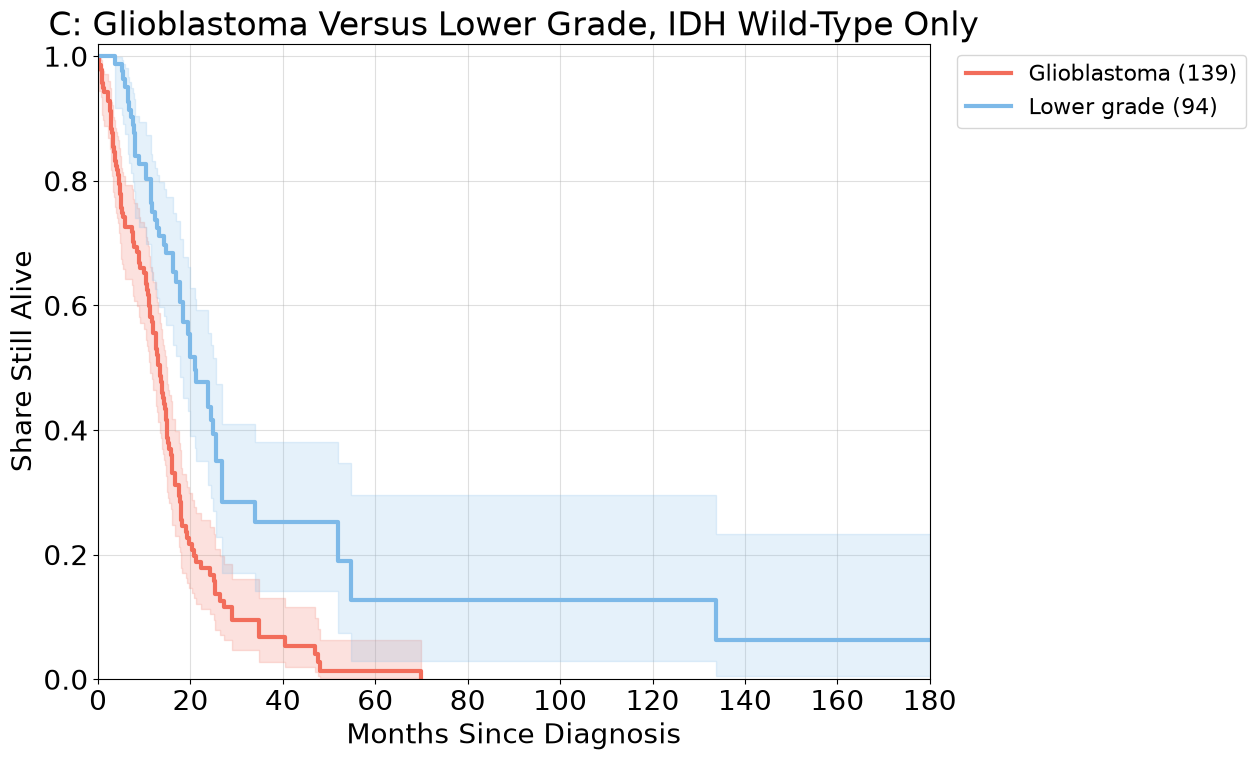

Comparison C
              patients  deaths        median_months
group                                              
Glioblastoma       139     113  13.3 (11.2 to 14.9)
Lower grade         94      50  21.0 (17.7 to 25.5)
Log-rank p-value: 6.15e-07




In [7]:
comparisons = {
    "A": ("compare_A", ["IDH wild-type", "IDH mutant"], "A: IDH Wild-Type Versus Mutant, Everyone", "p4-survival-A.png"),
    "B": ("compare_B", ["IDH wild-type", "IDH mutant"], "B: IDH Wild-Type Versus Mutant, Lower Grade Only", "p4-survival-B.png"),
    "C": ("compare_C", ["Glioblastoma", "Lower grade"], "C: Glioblastoma Versus Lower Grade, IDH Wild-Type Only", "p4-survival-C.png"),
}
comparison_colors = {"IDH wild-type": coral, "IDH mutant": light_blue, "Glioblastoma": coral, "Lower grade": light_blue}

for key, (column, order, title, filename) in comparisons.items():
    part = survival.dropna(subset=[column])
    table = survival_curves(part, column, order, comparison_colors, title, filename, max_months=180)
    first = part[part[column] == order[0]]
    second = part[part[column] == order[1]]
    test = logrank_test(first["OS_MONTHS"], second["OS_MONTHS"], first["event"], second["event"])
    print("Comparison " + key)
    print(table.to_string())
    print("Log-rank p-value:", "{:.2e}".format(test.p_value))
    print()
    print()

### Does the difference hold up after accounting for age and sex?
This uses a Cox model, which gives a hazard ratio for each input. For age I use 10 years as the unit, so the hazard ratio says how much the risk goes up for each extra 10 years. Model 2 also adds tumor grade, but only for patients with a grade, which leaves out the patients whose grade is missing.

In [8]:
model_data = survival.dropna(subset=["idh_group", "AGE", "SEX"]).copy()
model_data["idh_wild_type"] = (model_data["idh_group"] == "IDH wild-type").astype(int)
model_data["age_per_10_years"] = model_data["AGE"] / 10
model_data["male"] = (model_data["SEX"] == "Male").astype(int)
model_data["grade_number"] = model_data["GRADE"].map({"G2": 2, "G3": 3, "G4": 4})

columns = ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
names = {"exp(coef)": "hazard_ratio", "exp(coef) lower 95%": "low_95", "exp(coef) upper 95%": "high_95", "p": "p_value"}

model_1 = CoxPHFitter().fit(model_data[["OS_MONTHS", "event", "idh_wild_type", "age_per_10_years", "male"]],
                            duration_col="OS_MONTHS", event_col="event")
print("Model 1, IDH status with age and sex. Patients:", len(model_data))
print(model_1.summary[columns].rename(columns=names).round(3).to_string())
print()

with_grade = model_data.dropna(subset=["grade_number"])
model_2 = CoxPHFitter().fit(with_grade[["OS_MONTHS", "event", "idh_wild_type", "age_per_10_years", "male", "grade_number"]],
                            duration_col="OS_MONTHS", event_col="event")
print("Model 2, the same plus tumor grade. Patients:", len(with_grade))
print(model_2.summary[columns].rename(columns=names).round(3).to_string())

Model 1, IDH status with age and sex. Patients: 658
                  hazard_ratio  low_95  high_95  p_value
covariate                                               
idh_wild_type            6.399   4.625    8.853    0.000
age_per_10_years         1.467   1.316    1.636    0.000
male                     1.148   0.881    1.497    0.308

Model 2, the same plus tumor grade. Patients: 601
                  hazard_ratio  low_95  high_95  p_value
covariate                                               
idh_wild_type            4.009   2.649    6.067    0.000
age_per_10_years         1.355   1.205    1.524    0.000
male                     1.091   0.827    1.439    0.538
grade_number             1.930   1.481    2.513    0.000


### Do the genes from step 4 track with survival?
This asks whether a few genes from the earlier steps also separate patients by survival. For each gene I look only at IDH wild-type patients, so the answer is not just the IDH difference again. I split them at the middle into high and low activity and compare the curves. The Cox model also accounts for age and sex.

I picked three genes that I already had a reason to look at. If I tested many more, I would need the multiple-testing correction from step 4, because some would look important by luck.

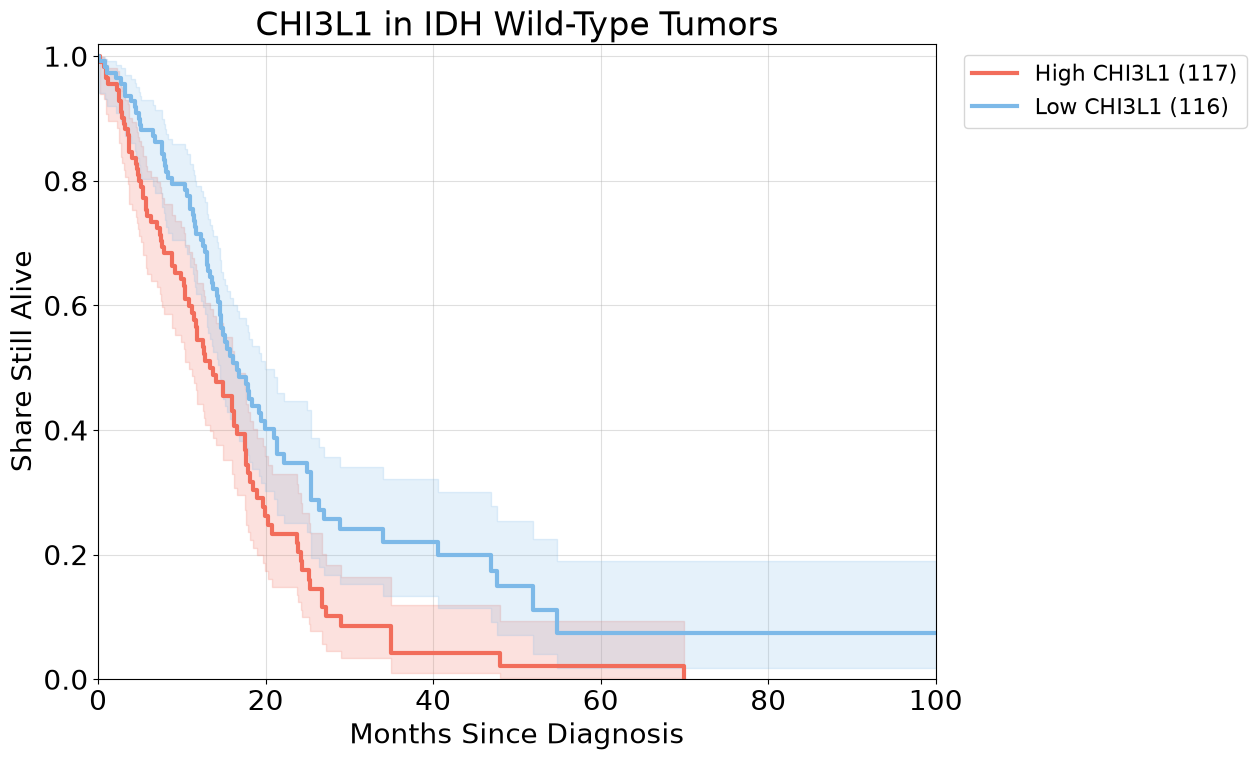

CHI3L1, IDH wild-type patients: 233
  Log-rank p-value, high versus low: 0.002
  Hazard ratio per 1 unit of log2 activity, after age and sex: 1.09 ( 1.02 to 1.16 ), p = 0.015



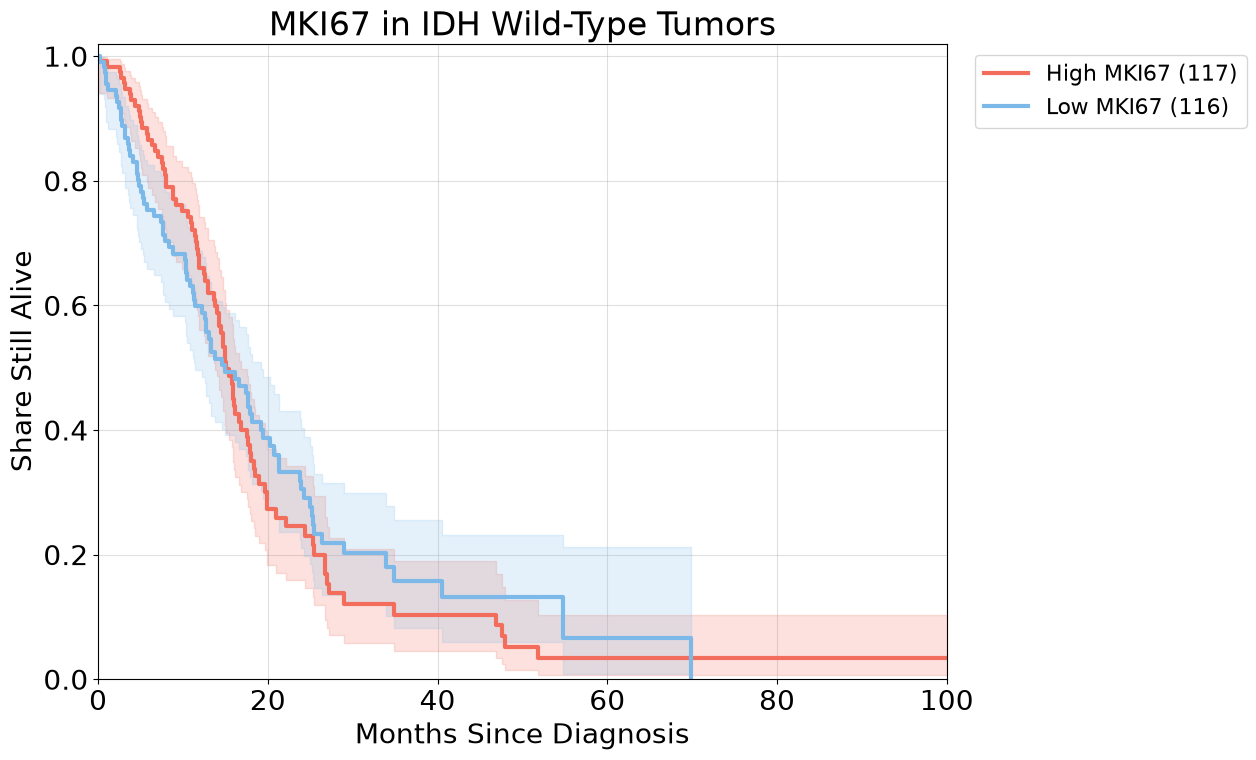

MKI67, IDH wild-type patients: 233
  Log-rank p-value, high versus low: 0.746
  Hazard ratio per 1 unit of log2 activity, after age and sex: 1.14 ( 1.04 to 1.25 ), p = 0.004



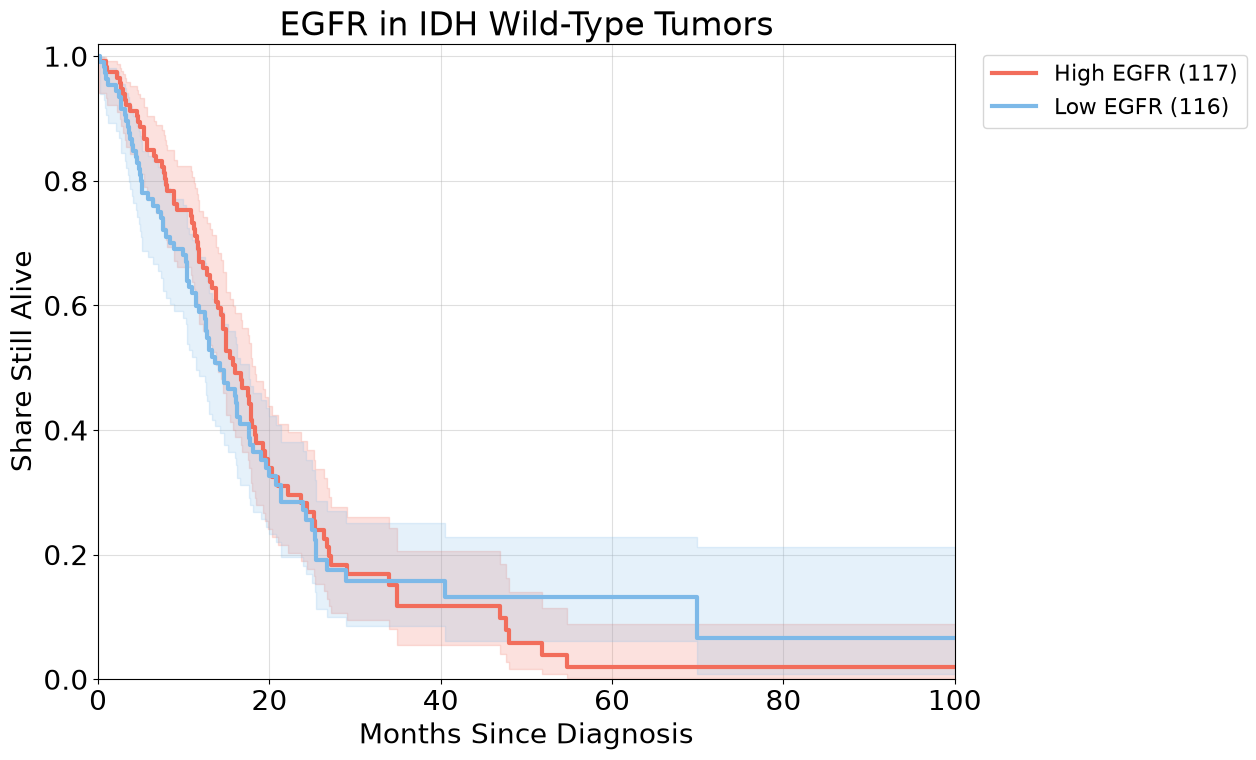

EGFR, IDH wild-type patients: 233
  Log-rank p-value, high versus low: 0.738
  Hazard ratio per 1 unit of log2 activity, after age and sex: 0.98 ( 0.93 to 1.04 ), p = 0.592



In [9]:
log_expr = pd.read_csv(data_dir / "processed" / "expression_log2.csv.gz", index_col=0)

wild_type = survival[survival["idh_group"] == "IDH wild-type"].dropna(subset=["AGE", "SEX"]).copy()
wild_type = wild_type[wild_type["PATIENT_ID"].isin(log_expr.columns)]

for gene in ["CHI3L1", "MKI67", "EGFR"]:
    if gene not in log_expr.index:
        print(gene + " is not in the gene activity table")
        continue

    values = log_expr.loc[gene, wild_type["PATIENT_ID"]].to_numpy()
    wild_type["gene_activity"] = values
    wild_type["level"] = np.where(values >= np.median(values), "High", "Low")

    fig, ax = plt.subplots(figsize=(13, 8))
    for level, color in [("High", coral), ("Low", light_blue)]:
        part = wild_type[wild_type["level"] == level]
        fitter = KaplanMeierFitter()
        fitter.fit(part["OS_MONTHS"], part["event"], label=level + " " + gene + " (" + str(len(part)) + ")")
        fitter.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2, color=color, linewidth=3)
    ax.set_title(gene + " in IDH Wild-Type Tumors")
    ax.set_xlabel("Months Since Diagnosis")
    ax.set_ylabel("Share Still Alive")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.4)
    ax.set_axisbelow(True)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=16)
    plt.tight_layout()
    plt.savefig("figures/p4-survival-gene-" + gene + ".png", dpi=150, bbox_inches="tight")
    plt.show()

    high = wild_type[wild_type["level"] == "High"]
    low = wild_type[wild_type["level"] == "Low"]
    test = logrank_test(high["OS_MONTHS"], low["OS_MONTHS"], high["event"], low["event"])

    cox_data = pd.DataFrame({"OS_MONTHS": wild_type["OS_MONTHS"], "event": wild_type["event"],
                             "gene_activity": wild_type["gene_activity"],
                             "age_per_10_years": wild_type["AGE"] / 10,
                             "male": (wild_type["SEX"] == "Male").astype(int)})
    cox = CoxPHFitter().fit(cox_data, duration_col="OS_MONTHS", event_col="event")
    row = cox.summary.loc["gene_activity"]
    print(gene + ", IDH wild-type patients:", len(wild_type))
    print("  Log-rank p-value, high versus low:", "{:.3f}".format(test.p_value))
    print("  Hazard ratio per 1 unit of log2 activity, after age and sex:", round(float(row["exp(coef)"]), 2),
          "(", round(float(row["exp(coef) lower 95%"]), 2), "to", round(float(row["exp(coef) upper 95%"]), 2), "), p =", "{:.3f}".format(float(row["p"])))
    print()